# AI meeting notes analyzer using LangGraph

## Objective
Convert a meeting transcript into structured meeting insights using a LangGraph workflow with multiple AI agents. The workflow produces:
1. Meeting summary (3–5 sentences)
2. Key discussion topics
3. Action items
4. Task owners
5. Priority level of each task (High Priority, Medium Priority or Low Priority)

## Scope
- Input: an English text meeting transcript, written as a paragraph, a conversation transcript or multiple speaker messages, pasted or uploaded as a .txt file, up to 40,000 characters (an operational limit for this version, not a model limit).
- The workflow runs in this notebook and in a Streamlit app.
- Topic extraction, meeting summary and action item extraction run in parallel. Priority classification runs only when action items are found; otherwise the report states "No action items identified in this meeting."
- Model: OpenAI gpt-6-luna. The action item extraction agent uses reasoning effort "medium"; the topic and summary agents use temperature 0 with reasoning effort "none". Priority classification uses fixed rules without a model call.

## Key assumptions
- Every output is supported by the transcript. Information the transcript does not state is reported as "Not specified" and is never inferred.
- A task without a named or self-identified owner is reported as "Owner: Not specified".
- Priority is assigned per task, based on urgency and deadline phrases linked to that task.
- Audio recordings are not accepted, because the input is defined as a written transcript.

## Step 1 : Project environment and dependency setup

**Objective:** Load the libraries used across the notebook, read the OpenAI API key securely and create the language model that every agent in the workflow uses.

In [1]:
import os
import re
import pandas as pd

from typing import TypedDict
from pydantic import BaseModel
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")

if not api_key:
    try:
        import streamlit as st
        api_key = st.secrets["OPENAI_API_KEY"]
    except Exception:
        api_key = None

if not api_key:
    raise RuntimeError(
        "OPENAI_API_KEY not found. Add it to .env locally or to Streamlit secrets when deployed."
    )

os.environ["OPENAI_API_KEY"] = api_key

llm = ChatOpenAI(
    model="gpt-6-luna",
    temperature=0,
    reasoning_effort="none"
)

## Step 2 : Test data setup

**Objective:** Confirm that the language model responds, then prepare the seven controlled test transcripts (T1–T7) used to check each agent and the full workflow.

| Test case | Description | What it tests |
|---|---|---|
| T1 | Website-performance example from the project brief | Named owners and High priority |
| T2 | Community garden review with updates only | No action items, so priority classification is skipped |
| T3 | Charity-run planning notes written as a paragraph | Named owners and an action with no owner |
| T4 | Restaurant team meeting with three tasks | High, Medium and Low priority, one per task |
| T5 | Empty input | Input validation |
| T6 | Sample meeting transcript (`data/sample_transcript.txt`) | A realistic, full-length meeting |
| T7 | Office-move follow-ups | Urgent and "by tomorrow" tasks, and unowned tasks kept separate from a related owned task |

In [2]:
print(llm.invoke("Reply with the single word OK.").content)

t1_transcript = "John: We need to improve the website performance. Sarah: Yes, page load time is too slow. David: I will optimize the database queries this week. Sarah: I will redesign the homepage layout. John: Let's try to finish these tasks before Friday."

t2_transcript = """Maria: Thanks for joining the quarterly review of the community garden. Overall, the season went well.
Tom: The tomato beds produced more than last year, and the new compost seemed to help.
Maria: Water usage was slightly higher in July because of the heat.
Priya: Visitor numbers on open days were similar to the spring season.
Tom: I wonder whether the herb section could be larger one day, but there is no need to change anything now.
Maria: Agreed. This was just an update meeting, so nothing needs to change. Thanks, everyone."""

t3_transcript = """The planning meeting for the annual charity run took place on Monday. Elena confirmed that she will book the park permit by Thursday. Marcus agreed to design the race-day poster. The group discussed the registration fee and agreed that the volunteer schedule must be shared with all volunteers before the event, but nobody was assigned to it. Someone also asked whether a second water station might be useful, but no decision was made."""

t4_transcript = """Restaurant Manager: The health inspector visits tomorrow morning, so the walk-in fridge door seal has to be repaired urgently. Head Chef, can you arrange the repair today?
Head Chef: Yes, I will call the repair company ASAP.
Restaurant Manager: Thanks. Next, the autumn menu. Sous Chef, please prepare three new dessert options for the tasting next week.
Sous Chef: I will have them ready for next week's tasting.
Restaurant Manager: Finally, I will update the staff photo board in the break room. There is no rush; it is a nice-to-have.
Head Chef: Sounds good."""

t4_expected_priorities = {
    "Head Chef": "High Priority",
    "Sous Chef": "Medium Priority",
    "Restaurant Manager": "Low Priority"
}

t5_transcript = ""

with open("data/sample_transcript.txt", encoding="utf-8") as file:
    t6_transcript = file.read()

t7_transcript = """Facilities Manager: We have a few follow-ups before the office move.
Facilities Manager: Leo, the broken fire door is urgent. Please get it repaired.
Leo: I will arrange the fire door repair.
Priya: I will send the new access cards by tomorrow.
Facilities Manager: Please record the furniture orders and delivery dates in one tracker.
Tom: I will update the moving budget with the furniture costs.
Facilities Manager: We need someone to book the moving van, but nobody has been assigned yet.
Facilities Manager: Maybe we could also repaint the reception at some point.
Nina: I will review the cleaning contract next week."""

t7_expected_actions = [
    {"owner": "Leo", "phrase": "fire door", "signal": "urgent", "priority": "High Priority"},
    {"owner": "Priya", "phrase": "access card", "signal": "tomorrow", "priority": "High Priority"},
    {"owner": "Not specified", "phrase": "furniture order", "signal": "", "priority": "Low Priority"},
    {"owner": "Tom", "phrase": "budget", "signal": "", "priority": "Low Priority"},
    {"owner": "Not specified", "phrase": "moving van", "signal": "", "priority": "Low Priority"},
    {"owner": "Nina", "phrase": "cleaning contract", "signal": "next week", "priority": "Medium Priority"}
]

test_cases = {
    "T1": t1_transcript,
    "T2": t2_transcript,
    "T3": t3_transcript,
    "T4": t4_transcript,
    "T5": t5_transcript,
    "T6": t6_transcript,
    "T7": t7_transcript
}

for case_id, transcript in test_cases.items():
    print(case_id, len(transcript), "characters")

OK
T1 241 characters
T2 531 characters
T3 435 characters
T4 561 characters
T5 0 characters
T6 3825 characters
T7 621 characters


**Insights**
- The language model replied "OK", confirming the API connection.
- T1–T4 range from 241 to 561 characters; T5 is empty (0 characters) to test input validation.
- T6, the sample transcript, has 3,825 characters across 47 speaker turns, within the 40,000-character limit.
- T7 has 621 characters and combines a task described as urgent, a task due "by tomorrow", two tasks without an owner next to a related task with an owner, and a suggestion that nobody agreed to.
- The sample file uses Windows-style line endings, which Python reads as standard line breaks.

## Step 3 : Expected action items for the sample transcript

**Objective:** Prepare a reference list of the action items in the sample meeting transcript (test case T6, loaded from `data/sample_transcript.txt` in Step 2), with the owner, deadline and priority of each. The list is used to evaluate the action item and priority agents on a realistic, full-length meeting.

This list was prepared by reading the sample transcript before any agent was run. It includes only commitments, explicit assignments, directives and accepted proposals, and merges restatements of the same task by the same owner. Owners and deadlines are recorded only when the transcript states them; otherwise they are "Not specified". Priorities follow the priority rubric. Agent output is compared with this list by task meaning, owner, deadline and priority, not by exact wording.

In [3]:
expected_t6_actions = [
    {"task": "Review the Android login module and check for missing error handling", "owner": "Mobile Developer", "deadline": "Not specified", "priority": "Low Priority"},
    {"task": "Prepare and share a detailed bug report with screenshots and logs", "owner": "QA Tester", "deadline": "within the next hour", "priority": "High Priority"},
    {"task": "Verify the authentication API for breaking changes, including whether the response format has changed", "owner": "Backend Developer", "deadline": "Not specified", "priority": "Low Priority"},
    {"task": "Test the login flow on Android 11, 12 and 13", "owner": "QA Tester", "deadline": "Not specified", "priority": "Low Priority"},
    {"task": "Check the server and API logs for authentication errors", "owner": "Backend Developer", "deadline": "right away", "priority": "High Priority"},
    {"task": "Inform the management team about the issue", "owner": "Not specified", "deadline": "Not specified", "priority": "Low Priority"},
    {"task": "Message the support team so they can update customers that a fix is in progress", "owner": "Customer Support Lead", "deadline": "Not specified", "priority": "Low Priority"},
    {"task": "Work on and push a fix for the login crash", "owner": "Mobile Developer", "deadline": "immediately after this meeting; by tomorrow if the issue is in the login module", "priority": "High Priority"},
    {"task": "Perform regression testing", "owner": "QA Tester", "deadline": "once the fix is ready", "priority": "Medium Priority"},
    {"task": "Test the authentication endpoints", "owner": "Backend Developer", "deadline": "after the fix is deployed", "priority": "Medium Priority"},
    {"task": "Document the issue and the resolution steps", "owner": "Not specified", "deadline": "Not specified", "priority": "Low Priority"},
    {"task": "Update the issue tracker with all findings", "owner": "QA Tester", "deadline": "Not specified", "priority": "Low Priority"},
    {"task": "Notify users about the fix", "owner": "Not specified", "deadline": "once the fix is deployed", "priority": "Medium Priority"},
    {"task": "Add better error handling so the app does not crash if the API fails", "owner": "Mobile Developer", "deadline": "Not specified", "priority": "Low Priority"},
    {"task": "Release the patch update to the Play Store once the issue is confirmed resolved", "owner": "Not specified", "deadline": "after testing", "priority": "Medium Priority"},
    {"task": "Provide an update", "owner": "Mobile Developer", "deadline": "by the end of the day", "priority": "High Priority"},
    {"task": "Provide an update and report any issues found", "owner": "Backend Developer", "deadline": "by the end of the day", "priority": "High Priority"},
    {"task": "Regroup to review progress", "owner": "Not specified", "deadline": "tomorrow morning", "priority": "High Priority"}
]

print("Expected action items:", len(expected_t6_actions))

for level in ["High Priority", "Medium Priority", "Low Priority"]:
    count = 0
    for action in expected_t6_actions:
        if action["priority"] == level:
            count = count + 1
    print(level, count)

Expected action items: 18
High Priority 6
Medium Priority 4
Low Priority 8


**Insights**
- The sample transcript contains 18 expected action items.
- 6 are High Priority, 4 Medium Priority and 8 Low Priority; a task with no deadline or urgency of its own is Low Priority, even though the meeting as a whole is urgent.

## Step 4 : State, constants and schemas

**Objective:** Define the shared workflow state, the input length limit and the structured-output schemas that the agents must follow, so every node reads and writes data in one agreed format.

In [4]:
MAX_TRANSCRIPT_CHARS = 40000
NO_ACTION_MESSAGE = "No action items identified in this meeting."


class MeetingState(TypedDict):
    transcript: str
    key_topics: list[str]
    meeting_summary: str
    action_items: list[dict]
    final_report: str


class TopicList(BaseModel):
    topics: list[str]


class ActionItem(BaseModel):
    task: str
    owner: str
    deadline: str


class ActionItemList(BaseModel):
    items: list[ActionItem]


print(list(MeetingState.__annotations__.keys()))
print(MAX_TRANSCRIPT_CHARS)

example_topics = TopicList(topics=["Budget review", "Office move"])
example_item = ActionItem(task="Send the budget report", owner="Not specified", deadline="by Monday")
example_items = ActionItemList(items=[example_item])
print("Valid examples accepted")

empty_items = ActionItemList(items=[])
print("Empty action list accepted:", len(empty_items.items), "items")

try:
    ActionItem(task="Send the budget report", deadline="by Monday")
except Exception as error:
    print("Action item without an owner rejected:", type(error).__name__)

['transcript', 'key_topics', 'meeting_summary', 'action_items', 'final_report']
40000
Valid examples accepted
Empty action list accepted: 0 items
Action item without an owner rejected: ValidationError


**Insights**
- The workflow state has five keys: transcript, key_topics, meeting_summary, action_items and final_report.
- Valid examples of all three schemas were accepted, including an empty action item list for meetings with no tasks.
- An action item without an owner was rejected with a ValidationError, so every extracted task must state an owner, even if it is "Not specified".

## Step 5 : Input node

**Objective:** Prepare the transcript for the agents by cleaning only its whitespace and line breaks, and reject empty input or input over the length limit before any model call is made.

In [5]:
def input_node(state: MeetingState) -> dict:
    text = state["transcript"]
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = text.strip()
    text = re.sub(r"\n\s*\n", "\n\n", text)

    if text == "":
        raise ValueError("The transcript is empty. Please paste or upload a meeting transcript.")

    if len(text) > MAX_TRANSCRIPT_CHARS:
        raise ValueError(f"The transcript has {len(text)} characters, which is more than the limit of {MAX_TRANSCRIPT_CHARS}.")

    return {"transcript": text}


messy_transcript = "  Anna: Hello.\r\n\r\n\r\n\r\nBen: I will send the notes.  \r\n"
print(repr(input_node({"transcript": messy_transcript})["transcript"]))

cleaned_t6 = input_node({"transcript": t6_transcript})["transcript"]
print("T6 words unchanged:", cleaned_t6.split() == t6_transcript.split())

boundary_result = input_node({"transcript": "a" * 40000})
print("40,000 characters accepted:", len(boundary_result["transcript"]))

rejection_cases = {
    "Empty input": t5_transcript,
    "Whitespace-only input": "   \n\n   ",
    "40,001 characters": "a" * 40001
}

for case_name, text in rejection_cases.items():
    try:
        input_node({"transcript": text})
        print(case_name, "accepted")
    except ValueError as error:
        print(case_name, "rejected:", error)

'Anna: Hello.\n\nBen: I will send the notes.'
T6 words unchanged: True
40,000 characters accepted: 40000
Empty input rejected: The transcript is empty. Please paste or upload a meeting transcript.
Whitespace-only input rejected: The transcript is empty. Please paste or upload a meeting transcript.
40,001 characters rejected: The transcript has 40001 characters, which is more than the limit of 40000.


**Insights**
- Windows line endings, leading and trailing spaces and repeated blank lines were cleaned; the words themselves were not changed.
- The sample transcript (T6) has identical words before and after cleaning.
- Empty and whitespace-only input are rejected before any model call, with a message asking for a transcript.
- Exactly 40,000 characters are accepted; 40,001 characters are rejected with a message stating the length and the limit.

## Step 6 : Topic extraction agent

**Objective:** Identify the main topics discussed in the meeting as a short list of distinct noun phrases, using only what the transcript contains.

In [6]:
TOPIC_PROMPT = """You are a meeting analyst. Read the meeting transcript below and identify the main topics that were discussed.

Rules:
- Write each topic as a short noun phrase of no more than six words.
- Include only topics that are actually discussed in the transcript. Do not add topics that are not mentioned.
- Each topic must be distinct. Do not repeat the same topic in different words.
- List only the main topics, usually 3 to 6. A short meeting may have fewer.
- Do not list greetings, thanks, or opening and closing remarks as topics.
- Do not list deadlines, dates or scheduling details as topics.
- If one candidate topic is a symptom, example, subtopic or supporting detail of another broader topic, keep only the broader main topic.
- When one candidate topic is the stated problem or symptom and another is the corresponding improvement goal for the same issue, combine them into one broader topic rather than listing them separately. Keep different pieces of work discussed to address the issue as separate topics.

Transcript:
{transcript}"""

topic_llm = llm.with_structured_output(TopicList)


def topic_extraction_node(state: MeetingState) -> dict:
    prompt = TOPIC_PROMPT.format(transcript=state["transcript"])
    result = topic_llm.invoke(prompt)
    return {"key_topics": result.topics}


topic_cases = {"T1": t1_transcript, "T6": t6_transcript}

for case_id, transcript in topic_cases.items():
    state = input_node({"transcript": transcript})
    topics = topic_extraction_node(state)["key_topics"]

    print(case_id)
    for number, topic in enumerate(topics, start=1):
        print(f"  {number}. {topic}")

    lower_topics = [topic.lower() for topic in topics]
    longest_topic = max([len(topic.split()) for topic in topics], default=0)

    print("  Topic count:", len(topics))
    print("  Longest topic (words):", longest_topic)
    print("  Duplicates:", len(lower_topics) != len(set(lower_topics)))

T1
  1. Website performance
  2. Database query optimization
  3. Homepage redesign
  Topic count: 3
  Longest topic (words): 3
  Duplicates: False
T6
  1. Android login crash investigation and fix
  2. Authentication API and backend changes
  3. Android compatibility and regression testing
  4. Customer and management communications
  5. Issue documentation and tracking
  Topic count: 5
  Longest topic (words): 6
  Duplicates: False


**Insights**
- T1 returned 3 topics and T6 returned 5, each of no more than 6 words, with no duplicates.
- For T1, the topics match the three topics in the project brief's example: website performance, database query optimization and homepage redesign.
- For T6, every topic is supported by the transcript: the login crash investigation and fix, the authentication API changes, testing on Android versions, communication with customers and management, and documentation and tracking of the issue.

## Step 7 : Meeting summary agent

**Objective:** Write a concise summary of 3–5 sentences covering what the meeting was about, the main issues discussed and the agreed next steps, using only information in the transcript.

In [7]:
SUMMARY_PROMPT = """You are a meeting analyst. Read the meeting transcript below and write a concise summary of the meeting.

Rules:
- Write between 3 and 5 complete sentences as a single paragraph.
- Explain what the meeting was about, the main issues discussed, and the next steps that were agreed, if any.
- Use only information stated in the transcript. Do not add facts, names, numbers or dates that are not in the transcript.
- Do not use bullet points, headings or lists.
- Return only the summary text.

Transcript:
{transcript}"""


def meeting_summary_node(state: MeetingState) -> dict:
    prompt = SUMMARY_PROMPT.format(transcript=state["transcript"])
    summary = llm.invoke(prompt).content.strip()
    return {"meeting_summary": summary}


def count_sentences(text):
    return len(re.findall(r"[.!?](\s|$)", text))


summary_cases = {"T1": t1_transcript, "T6": t6_transcript}

for case_id, transcript in summary_cases.items():
    state = input_node({"transcript": transcript})
    summary = meeting_summary_node(state)["meeting_summary"]

    print(case_id)
    print(summary)
    print("Sentence count:", count_sentences(summary))
    print()

T1
The meeting focused on improving website performance, particularly the slow page load time. David will optimize the database queries, and Sarah will redesign the homepage layout. The team aims to finish both tasks before Friday.
Sentence count: 3

T6
The meeting focused on urgent reports of the mobile app crashing during login, mainly affecting Android users, with the issue appearing around the time of a recent authentication service update. The team discussed whether the cause was a backend API change or how the Android app handles API responses, and agreed to investigate both components. The mobile developer will review the Android login module and improve error handling, the backend developer will check the API and server logs, and QA will document the issue and test the login flow on Android 11, 12, and 13. After a fix is ready, QA will run regression tests and the backend developer will test the authentication endpoints; the team will release a Play Store patch and notify users

**Insights**
- The T1 summary has 3 sentences and the T6 summary has 4, within the required 3–5.
- Both summaries cover what the meeting was about, the main issues and the agreed next steps, and every statement is supported by its transcript.
- The T1 summary names both task owners and the "before Friday" target; the T6 summary refers to participants by the roles used as speaker labels in the transcript.

## Step 8 : Action item extraction agent

**Objective:** Extract the genuine action items from the meeting, each with a task description, an owner and a deadline taken only from the transcript, and number them so later steps can refer to each task.

In [8]:
ACTION_PROMPT = """You are a meeting analyst. Read the meeting transcript below and extract the action items.

An action item is a specific task that someone is expected to do after the meeting. Include only:
- Commitments or clear offers to take responsibility for a specific future task, for example "I will ...", "Let me ..." or "I can ...". Do not include statements that merely describe what the speaker is capable of doing.
- Assignments, where a task is given to a named person or role.
- Directives, where a specific task is requested, for example "Please ...".
- Agreed next steps, where a specific, concrete action is proposed with "Let's ..." or "We should ..." and is not rejected, or a proposal that another participant accepts.
- Unassigned tasks, where the meeting explicitly states that someone is needed to perform a specific future task but nobody is assigned, for example "We need someone to ...". Use "Not specified" as the owner.

Do not include:
- Broad goals or general "we need to ..." statements are not action items. Do not extract them unless the transcript explicitly indicates that someone is needed to take responsibility for the specific task.
- Questions without an agreed answer, suggestions nobody agreed to, or speculation such as "could be" or "might be".
- Observations, status updates, or work already done before the meeting.
- Statements that only set a deadline for tasks already mentioned. Use that timing as the deadline of those tasks instead.
- Requests to prioritise, focus on or treat an issue as urgent when they express urgency rather than a separate concrete task or deliverable.

For each action item, provide:
- task: a short description of the task, using only what the transcript says.
- owner: if a speaker commits to the task, use their speaker label exactly as written in the transcript. If the task is assigned to a named person or role, use that name or role exactly as written. If a speaker agrees to take on the same commitment as another speaker, list it as a separate action item for that speaker. If nobody is responsible, write "Not specified". Never guess an owner.
- deadline: copy the time phrase exactly as written in the transcript. If a time phrase applies to several tasks, use it for each of them. If there is more than one time phrase for a task, separate them with a semicolon. If no time is stated, write "Not specified". Never convert a phrase into a date and never invent a deadline.
- If the transcript explicitly states that a specific task is urgent, for example "urgent", "urgently" or "ASAP", also include that urgency word in the deadline, separated by a semicolon from any time phrase. If urgency is stated but no time, use the urgency word as the deadline. Do this only when the urgency is clearly linked to that task.
- If a deadline is conditional, preserve the condition together with the time phrase so the deadline is not presented as unconditional.
- A deadline may be inherited from the immediately preceding context only when the speaker clearly adopts the same timing, for example by explicitly agreeing to the same commitment or timing. Do not infer timing from distant context.

Additional rules:
- Do not treat a general meeting-level urgency or timing statement as a deadline for a specific task unless the transcript clearly links that timing to that task. Do not carry timing forward to later tasks merely because they appear after the statement.
- A first-person commitment to perform a specific task can still count when phrased cautiously, such as "should be able to", if the intended action is clear. Preserve any stated timing and condition together.

List each action once. If the same owner restates or confirms the same task, for example by accepting an assignment, list it as one item and keep all of its time phrases. Never combine actions that have different owners, never combine an action without an owner with an action that has an owner, and never give an action an owner because of a related action. Keep different pieces of work as separate items.

If there are no action items, return an empty list.

Transcript:
{transcript}"""

action_llm = ChatOpenAI(
    model="gpt-6-luna",
    reasoning_effort="medium"
).with_structured_output(ActionItemList)


def action_extraction_node(state: MeetingState) -> dict:
    prompt = ACTION_PROMPT.format(transcript=state["transcript"])
    result = action_llm.invoke(prompt)
    action_items = []
    seen = []
    for item in result.items:
        task_key = " ".join(item.task.lower().split())
        owner_key = " ".join(item.owner.lower().split())
        deadline_key = " ".join(item.deadline.lower().split())
        key = (task_key, owner_key, deadline_key)
        if key in seen:
            continue
        seen.append(key)
        action_items.append({
            "task_id": len(action_items) + 1,
            "task": item.task,
            "owner": item.owner,
            "deadline": item.deadline
        })
    return {"action_items": action_items}


def owners_from_transcript(items, transcript):
    for item in items:
        if item["owner"] != "Not specified" and item["owner"] not in transcript:
            return False
    return True


def deadlines_from_transcript(items, transcript):
    for item in items:
        if item["deadline"] == "Not specified":
            continue
        for phrase in item["deadline"].split(";"):
            if phrase.strip().lower() not in transcript.lower():
                return False
    return True


action_cases = {
    "T1": t1_transcript,
    "T2": t2_transcript,
    "T3": t3_transcript,
    "T4": t4_transcript,
    "T6": t6_transcript
}

for case_id, transcript in action_cases.items():
    state = input_node({"transcript": transcript})
    items = action_extraction_node(state)["action_items"]

    print(case_id)
    for item in items:
        print(f"  {item['task_id']}. {item['task']} | Owner: {item['owner']} | Deadline: {item['deadline']}")

    task_ids = [item["task_id"] for item in items]

    print("  Item count:", len(items))
    print("  Task IDs 1..n:", task_ids == list(range(1, len(items) + 1)))
    print("  Owners from transcript:", owners_from_transcript(items, state["transcript"]))
    print("  Deadlines from transcript:", deadlines_from_transcript(items, state["transcript"]))
    print()

T1
  1. Optimize the database queries | Owner: David | Deadline: this week; before Friday
  2. Redesign the homepage layout | Owner: Sarah | Deadline: before Friday
  Item count: 2
  Task IDs 1..n: True
  Owners from transcript: True
  Deadlines from transcript: True

T2
  Item count: 0
  Task IDs 1..n: True
  Owners from transcript: True
  Deadlines from transcript: True

T3
  1. Book the park permit | Owner: Elena | Deadline: by Thursday
  2. Design the race-day poster | Owner: Marcus | Deadline: Not specified
  3. Share the volunteer schedule with all volunteers | Owner: Not specified | Deadline: before the event
  Item count: 3
  Task IDs 1..n: True
  Owners from transcript: True
  Deadlines from transcript: True

T4
  1. Arrange the walk-in fridge door seal repair by calling the repair company | Owner: Head Chef | Deadline: today; ASAP; urgently
  2. Prepare three new dessert options for the tasting | Owner: Sous Chef | Deadline: next week; next week's tasting
  3. Update the staf

**Insights**
- T1 returned exactly 2 action items, for David and Sarah, with "before Friday" applied to both tasks as a deadline instead of being listed as a separate task.
- T2 returned no action items; T3 returned 3, including the volunteer schedule with owner "Not specified", and the unanswered water-station question was not extracted.
- T4 returned the 3 expected tasks, owned by Head Chef, Sous Chef and Restaurant Manager; the Head Chef's deadline "today; ASAP; urgently" includes "urgently", which the Restaurant Manager stated for that repair.
- T6 returned 21 action items: every owner is a speaker label from the transcript or "Not specified", the unowned request to document the issue stays separate from the QA Tester's issue-tracker update, and no question, observation or request to prioritise the issue was extracted as a task.
- In T6, the conditional "by tomorrow" timing of the fix and the end-of-day timing of both updates are kept, and the deadline check confirms that every deadline phrase in all five cases appears in the transcript.
- In T6, some closely related commitments are listed as separate items: the two API checks, the server and API log reviews, and the start and delivery of the fix.
- The action item agent uses reasoning effort "medium" without a fixed temperature, so its output can vary slightly between runs.

## Step 9 : Action check and router

**Objective:** Decide, without a model call, whether the meeting has action items, so the workflow either classifies their priority or skips that step when there are none.

In [9]:
def action_check_node(state: MeetingState) -> dict:
    return {}


def route_actions(state: MeetingState) -> str:
    if len(state["action_items"]) > 0:
        return "prioritise"
    return "skip"


empty_state = {"action_items": []}
filled_state = {"action_items": [{"task_id": 1, "task": "Send the budget report", "owner": "Not specified", "deadline": "Not specified"}]}

print("Empty action list route:", route_actions(empty_state))
print("Non-empty action list route:", route_actions(filled_state))
print("Action check node update:", action_check_node(filled_state))

Empty action list route: skip
Non-empty action list route: prioritise
Action check node update: {}


**Insights**
- A meeting with no action items is routed to "skip", so priority classification is not run and the report can state that no action items were identified.
- A meeting with at least one action item is routed to "prioritise".
- The action check node returns an empty update, so it does not change the workflow state before routing.

## Step 10 : Priority classification node

**Objective:** Assign High, Medium or Low Priority to each action item with fixed rules that read only the urgency and timing words in that task and its deadline, so the same input always receives the same priority and urgency stated for the whole meeting does not spread to unrelated tasks.

In [10]:
HIGH_PRIORITY_PHRASES = [
    "urgent", "urgently", "asap", "immediately", "right away",
    "today", "tonight", "end of day", "end of the day", "tomorrow",
    "within the hour", "within the next hour", "within an hour", "this week"
]

WEEKDAYS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]

MEDIUM_PRIORITY_PHRASES = ["next week", "next month", "soon", "later", "once", "after", "when", "before"]

NEGATED_URGENCY_PHRASES = ["not urgently", "not urgent", "no rush"]


def contains_phrase(text, phrase):
    return re.search(r"\b" + phrase + r"\b", text) is not None


def classify_priority(task, deadline):
    text = (task + " " + deadline).lower()

    for phrase in NEGATED_URGENCY_PHRASES:
        text = re.sub(r"\b" + phrase + r"\b", " ", text)

    for phrase in HIGH_PRIORITY_PHRASES:
        if contains_phrase(text, phrase):
            return "High Priority"

    for day in WEEKDAYS:
        if contains_phrase(text, "next " + day):
            return "Medium Priority"
        if contains_phrase(text, day):
            return "High Priority"

    for phrase in MEDIUM_PRIORITY_PHRASES:
        if contains_phrase(text, phrase):
            return "Medium Priority"

    return "Low Priority"


def priority_classification_node(state: MeetingState) -> dict:
    prioritised_items = []
    for item in state["action_items"]:
        prioritised_item = dict(item)
        prioritised_item["priority"] = classify_priority(item["task"], item["deadline"])
        prioritised_items.append(prioritised_item)
    return {"action_items": prioritised_items}


def fields_unchanged(before, after):
    if len(before) != len(after):
        return False
    for index in range(len(before)):
        for key in ["task_id", "task", "owner", "deadline"]:
            if before[index][key] != after[index][key]:
                return False
    return True


def print_priorities(case_id, items):
    print(case_id)
    for item in items:
        print(f"  {item['task_id']}. {item['task']} | Owner: {item['owner']} | Deadline: {item['deadline']} | {item['priority']}")


t1_action_items = [
    {"task_id": 1, "task": "Optimize the database queries", "owner": "David", "deadline": "this week; before Friday"},
    {"task_id": 2, "task": "Redesign the homepage layout", "owner": "Sarah", "deadline": "before Friday"}
]

t4_action_items = [
    {"task_id": 1, "task": "Call the repair company about repairing the walk-in fridge door seal.", "owner": "Head Chef", "deadline": "today; ASAP"},
    {"task_id": 2, "task": "Prepare three new dessert options for the tasting.", "owner": "Sous Chef", "deadline": "next week; next week's tasting"},
    {"task_id": 3, "task": "Update the staff photo board in the break room.", "owner": "Restaurant Manager", "deadline": "Not specified"}
]

t1_result = priority_classification_node({"action_items": t1_action_items})["action_items"]
print_priorities("T1", t1_result)

all_high = True
for item in t1_result:
    if item["priority"] != "High Priority":
        all_high = False
print("  Both tasks High Priority:", all_high)
print("  Fields unchanged:", fields_unchanged(t1_action_items, t1_result))
print()

t4_result = priority_classification_node({"action_items": t4_action_items})["action_items"]
print_priorities("T4", t4_result)

t4_matches = True
for item in t4_result:
    if item["priority"] != t4_expected_priorities[item["owner"]]:
        t4_matches = False
print("  T4 matches expected:", t4_matches)
print("  Fields unchanged:", fields_unchanged(t4_action_items, t4_result))
print()

t6_action_items = []
for number, action in enumerate(expected_t6_actions, start=1):
    t6_action_items.append({
        "task_id": number,
        "task": action["task"],
        "owner": action["owner"],
        "deadline": action["deadline"]
    })

t6_result = priority_classification_node({"action_items": t6_action_items})["action_items"]

print("T6 (expected action list)")
matches = 0
for index in range(len(t6_result)):
    item = t6_result[index]
    expected_priority = expected_t6_actions[index]["priority"]
    if item["priority"] == expected_priority:
        matches = matches + 1
        status = "match"
    else:
        status = "expected " + expected_priority
    print(f"  {item['task_id']}. {item['task']} | Deadline: {item['deadline']} | {item['priority']} | {status}")

print("  Matches with expected priorities:", matches, "of", len(t6_result))
print("  Fields unchanged:", fields_unchanged(t6_action_items, t6_result))
print()

phrase_checks = {
    "by next Monday": "Medium Priority",
    "next steps before Friday": "High Priority",
    "by Friday": "High Priority",
    "within an hour": "High Priority",
    "immediately after the review": "High Priority",
    "once the budget is approved": "Medium Priority",
    "before the launch": "Medium Priority",
    "next week's workshop": "Medium Priority",
    "Not specified": "Low Priority",
    "not urgent": "Low Priority",
    "not urgent, but by tomorrow": "High Priority",
    "urgent": "High Priority",
    "no rush": "Low Priority"
}

print("Deadline phrase checks")
for deadline, expected_priority in phrase_checks.items():
    result = classify_priority("Prepare the report", deadline)
    if result == expected_priority:
        status = "match"
    else:
        status = "expected " + expected_priority
    print(f"  {deadline} -> {result} | {status}")

T1
  1. Optimize the database queries | Owner: David | Deadline: this week; before Friday | High Priority
  2. Redesign the homepage layout | Owner: Sarah | Deadline: before Friday | High Priority
  Both tasks High Priority: True
  Fields unchanged: True

T4
  1. Call the repair company about repairing the walk-in fridge door seal. | Owner: Head Chef | Deadline: today; ASAP | High Priority
  2. Prepare three new dessert options for the tasting. | Owner: Sous Chef | Deadline: next week; next week's tasting | Medium Priority
  3. Update the staff photo board in the break room. | Owner: Restaurant Manager | Deadline: Not specified | Low Priority
  T4 matches expected: True
  Fields unchanged: True

T6 (expected action list)
  1. Review the Android login module and check for missing error handling | Deadline: Not specified | Low Priority | match
  2. Prepare and share a detailed bug report with screenshots and logs | Deadline: within the next hour | High Priority | match
  3. Verify the au

**Insights**
- Both T1 tasks are High Priority because their deadlines contain "this week" and "Friday", matching the project brief's example.
- The T4 tasks are High, Medium and Low Priority, matching the expected priority of each task.
- All 18 tasks in the expected list for the sample transcript receive their expected priority (6 High, 4 Medium, 8 Low), and their tasks, owners and deadlines are unchanged.
- Tasks without a deadline or urgency word of their own, such as informing the management team, are Low Priority even though the meeting as a whole is urgent.
- The phrase checks confirm the order of the rules: "immediately after the review" is High even though it contains "after", and "by next Monday" is Medium while "by Friday" is High.
- The negation checks show that "not urgent" and "no rush" on their own give Low Priority, "urgent" gives High Priority, and "not urgent, but by tomorrow" is High Priority because of "tomorrow".

## Step 11 : Final output node

**Objective:** Combine the outputs of all agents into one structured meeting report with the five sections the brief requires, in the brief's order, using code only and no model call.

In [11]:
REPORT_HEADINGS = ["1. Meeting Summary", "2. Key Topics", "3. Action Items", "4. Task Owners", "5. Priority Level"]


def final_output_node(state: MeetingState) -> dict:
    report_lines = []

    report_lines.append("1. Meeting Summary")
    report_lines.append(state["meeting_summary"])
    report_lines.append("")

    report_lines.append("2. Key Topics")
    if len(state["key_topics"]) == 0:
        report_lines.append("No key topics identified.")
    for number, topic in enumerate(state["key_topics"], start=1):
        report_lines.append(f"{number}. {topic}")
    report_lines.append("")

    action_items = state["action_items"]

    if len(action_items) == 0:
        for heading in ["3. Action Items", "4. Task Owners", "5. Priority Level"]:
            report_lines.append(heading)
            report_lines.append(NO_ACTION_MESSAGE)
            report_lines.append("")
        return {"final_report": "\n".join(report_lines).strip()}

    report_lines.append("3. Action Items")
    for item in action_items:
        report_lines.append(f"{item['task_id']}. Task: {item['task']} | Owner: {item['owner']} | Deadline: {item['deadline']} | Priority: {item['priority']}")
    report_lines.append("")

    report_lines.append("4. Task Owners")
    owners = []
    for item in action_items:
        if item["owner"] not in owners:
            owners.append(item["owner"])
    for owner in owners:
        report_lines.append(f"Owner: {owner}")
        for item in action_items:
            if item["owner"] == owner:
                report_lines.append(f"- {item['task']}")
    report_lines.append("")

    report_lines.append("5. Priority Level")
    for level in ["High Priority", "Medium Priority", "Low Priority"]:
        level_tasks = []
        for item in action_items:
            if item["priority"] == level:
                level_tasks.append(item["task"])
        report_lines.append(f"{level} ({len(level_tasks)})")
        if len(level_tasks) == 0:
            report_lines.append("- None")
        for task in level_tasks:
            report_lines.append(f"- {task}")

    return {"final_report": "\n".join(report_lines)}


def headings_in_order(report):
    positions = []
    for heading in REPORT_HEADINGS:
        if heading not in report:
            return False
        positions.append(report.index(heading))
    return positions == sorted(positions)


state_with_actions = {
    "meeting_summary": "The team reviewed the quarterly budget and the planned office move. Two follow-up tasks were assigned, and one agreed task has no owner yet. The next review will take place after the move.",
    "key_topics": ["Quarterly budget review", "Office move planning"],
    "action_items": [
        {"task_id": 1, "task": "Send the budget report", "owner": "Anna", "deadline": "by Friday", "priority": "High Priority"},
        {"task_id": 2, "task": "Compare moving companies", "owner": "Ben", "deadline": "next week", "priority": "Medium Priority"},
        {"task_id": 3, "task": "Book a room for the next review", "owner": "Not specified", "deadline": "Not specified", "priority": "Low Priority"}
    ]
}

report_with_actions = final_output_node(state_with_actions)["final_report"]
print(report_with_actions)
print()

priority_total = 0
for count in re.findall(r"Priority \((\d+)\)", report_with_actions):
    priority_total = priority_total + int(count)

print("Headings in brief order:", headings_in_order(report_with_actions))
print("Owner: Not specified shown:", "Owner: Not specified" in report_with_actions)
print("Priority counts add up to the number of tasks:", priority_total == len(state_with_actions["action_items"]))
print()

state_without_actions = {
    "meeting_summary": "The team shared progress updates on the quarterly budget. No changes were agreed. The next review date was not discussed.",
    "key_topics": ["Quarterly budget update"],
    "action_items": []
}

report_without_actions = final_output_node(state_without_actions)["final_report"]
print(report_without_actions)
print()

print("Headings in brief order:", headings_in_order(report_without_actions))
print("No-action message shown in sections 3 to 5:", report_without_actions.count(NO_ACTION_MESSAGE) == 3)
print("No owners or priority counts:", "Owner:" not in report_without_actions and "Priority (" not in report_without_actions)

empty_topics_state = {"meeting_summary": "Short check-in.", "key_topics": [], "action_items": []}
print("Empty topic list handled:", "No key topics identified." in final_output_node(empty_topics_state)["final_report"])

1. Meeting Summary
The team reviewed the quarterly budget and the planned office move. Two follow-up tasks were assigned, and one agreed task has no owner yet. The next review will take place after the move.

2. Key Topics
1. Quarterly budget review
2. Office move planning

3. Action Items
1. Task: Send the budget report | Owner: Anna | Deadline: by Friday | Priority: High Priority
2. Task: Compare moving companies | Owner: Ben | Deadline: next week | Priority: Medium Priority
3. Task: Book a room for the next review | Owner: Not specified | Deadline: Not specified | Priority: Low Priority

4. Task Owners
Owner: Anna
- Send the budget report
Owner: Ben
- Compare moving companies
Owner: Not specified
- Book a room for the next review

5. Priority Level
High Priority (1)
- Send the budget report
Medium Priority (1)
- Compare moving companies
Low Priority (1)
- Book a room for the next review

Headings in brief order: True
Owner: Not specified shown: True
Priority counts add up to the num

**Insights**
- The report contains the five sections required by the brief, in order: Meeting Summary, Key Topics, Action Items, Task Owners and Priority Level.
- The unowned task is shown as "Owner: Not specified" in both the action list and the task owners section.
- The priority section always shows High, Medium and Low Priority with their counts, which add up to the number of action items.
- When no action items are found, sections 3 to 5 each state "No action items identified in this meeting." and no owners or priorities are shown.
- If no key topics are returned, the report states "No key topics identified." instead of leaving the section empty.

## Step 12 : Graph construction

**Objective:** Connect the nodes into the LangGraph workflow: the input node fans out to the topic, summary and action item agents, which run in parallel and join at the action check, followed by conditional routing either to priority classification or directly to the final report.

In [12]:
builder = StateGraph(MeetingState)

builder.add_node("input", input_node)
builder.add_node("topic_extraction", topic_extraction_node)
builder.add_node("meeting_summary", meeting_summary_node)
builder.add_node("action_extraction", action_extraction_node)
builder.add_node("action_check", action_check_node)
builder.add_node("priority_classification", priority_classification_node)
builder.add_node("final_output", final_output_node)

builder.add_edge(START, "input")
builder.add_edge("input", "topic_extraction")
builder.add_edge("input", "meeting_summary")
builder.add_edge("input", "action_extraction")
builder.add_edge(["topic_extraction", "meeting_summary", "action_extraction"], "action_check")
builder.add_conditional_edges(
    "action_check",
    route_actions,
    {"prioritise": "priority_classification", "skip": "final_output"}
)
builder.add_edge("priority_classification", "final_output")
builder.add_edge("final_output", END)

meeting_graph = builder.compile()

workflow_groups = [
    [("__start__", "input")],
    [("input", "topic_extraction"), ("input", "meeting_summary"), ("input", "action_extraction")],
    [("topic_extraction", "action_check"), ("meeting_summary", "action_check"), ("action_extraction", "action_check")],
    [("action_check", "priority_classification"), ("action_check", "final_output")],
    [("priority_classification", "final_output"), ("final_output", "__end__")]
]

expected_edges = []
for group in workflow_groups:
    for edge_pair in group:
        expected_edges.append(edge_pair)

graph_view = meeting_graph.get_graph()

node_names = []
for name in graph_view.nodes:
    if name not in ["__start__", "__end__"]:
        node_names.append(name)

actual_edges = []
route_labels = {}
for edge in graph_view.edges:
    edge_pair = (edge.source, edge.target)
    actual_edges.append(edge_pair)
    if edge.conditional:
        route_labels[edge_pair] = edge.data

print("Nodes:", ", ".join(node_names))
print("Node count:", len(node_names))
print()
print("Workflow edges:")
for group in workflow_groups:
    for edge_pair in group:
        if edge_pair in actual_edges:
            source = edge_pair[0].replace("__start__", "START")
            target = edge_pair[1].replace("__end__", "END")
            line = f"  {source} -> {target}"
            if edge_pair in route_labels:
                line = line + f" (conditional: {route_labels[edge_pair]})"
            print(line)
    print()

print("Edge count:", len(actual_edges))
print("Edges match the agreed design:", sorted(actual_edges) == sorted(expected_edges))

Nodes: input, topic_extraction, meeting_summary, action_extraction, action_check, priority_classification, final_output
Node count: 7

Workflow edges:
  START -> input

  input -> topic_extraction
  input -> meeting_summary
  input -> action_extraction

  topic_extraction -> action_check
  meeting_summary -> action_check
  action_extraction -> action_check

  action_check -> priority_classification (conditional: prioritise)
  action_check -> final_output (conditional: skip)

  priority_classification -> final_output
  final_output -> END

Edge count: 11
Edges match the agreed design: True


**Insights**
- The compiled graph has 7 nodes and 11 edges, matching the agreed design.
- The input node fans out to the topic extraction, meeting summary and action item agents, and all three join at the action check.
- The action check has two conditional routes: "prioritise" leads to priority classification and "skip" leads directly to the final output.
- Both routes end at the final output node, which leads to the end of the workflow.

## Step 13 : Graph visualisation

**Objective:** Display the compiled LangGraph workflow as a text diagram and as an image, showing the parallel agents, the join at the action check and the two conditional routes.

                                 +-----------+                                  
                                 | __start__ |                                  
                                 +-----------+                                  
                                       *                                        
                                       *                                        
                                       *                                        
                                   +-------+                                    
                                 **| input |**                                  
                            *****  +-------+  *****                             
                       *****           *           *****                        
                  *****                *                *****                   
               ***                     *                     ***                
+-------------------+       

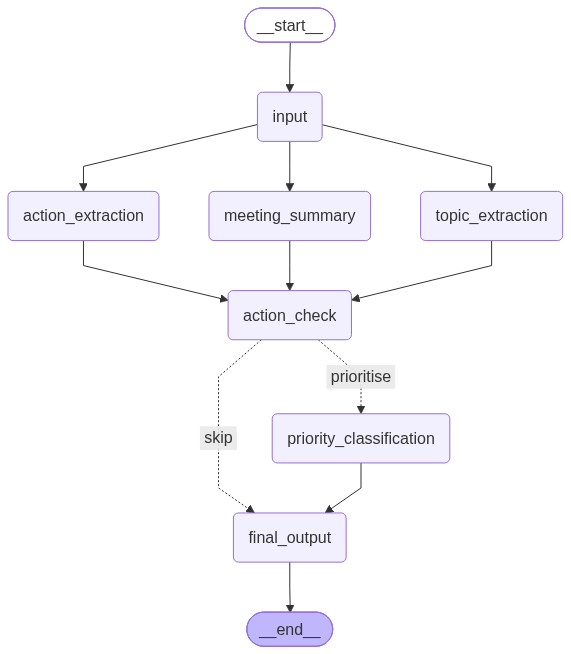

In [13]:
meeting_graph.get_graph().print_ascii()

try:
    display(Image(meeting_graph.get_graph().draw_mermaid_png()))
except Exception as error:
    print("The graph image could not be rendered:", type(error).__name__)

**Insights**
- The text diagram and the image show the same workflow: the input node branches to the action item, meeting summary and topic extraction agents, which join at the action check.
- In the image, the two conditional routes from the action check are drawn as dashed lines labelled "prioritise" (to priority classification) and "skip" (directly to the final output).
- Both routes end at the final output node, which leads to the end of the workflow.

## Step 14 : End-to-end runs on both paths

**Objective:** Run the complete workflow on a meeting with action items (T1) and a meeting without action items (T2), and confirm from the nodes that actually ran that each meeting takes the correct route and produces the full five-section report.

In [14]:
def run_meeting(transcript):
    nodes_run = []
    final_report = ""
    prioritised_items = []
    for update in meeting_graph.stream({"transcript": transcript}, stream_mode="updates"):
        for node_name, node_output in update.items():
            nodes_run.append(node_name)
            if node_name == "priority_classification":
                prioritised_items = node_output["action_items"]
            if node_name == "final_output":
                final_report = node_output["final_report"]
    return nodes_run, final_report, prioritised_items


t1_nodes, t1_report, t1_prioritised = run_meeting(t1_transcript)

print("T1")
print("Nodes run:", " -> ".join(t1_nodes))
print()
print(t1_report)
print()

t1_owners = []
t1_all_high = True
for item in t1_prioritised:
    t1_owners.append(item["owner"])
    if item["priority"] != "High Priority":
        t1_all_high = False

print("Priority classification ran once:", t1_nodes.count("priority_classification") == 1)
print("Final output ran once:", t1_nodes.count("final_output") == 1)
print("Five sections in brief order:", headings_in_order(t1_report))
print("Owners are David and Sarah:", sorted(t1_owners) == ["David", "Sarah"])
print("Both tasks High Priority:", t1_all_high and len(t1_prioritised) == 2)
print()

t2_nodes, t2_report, t2_prioritised = run_meeting(t2_transcript)

print("T2")
print("Nodes run:", " -> ".join(t2_nodes))
print()
print(t2_report)
print()

print("Priority classification skipped:", t2_nodes.count("priority_classification") == 0)
print("Final output ran once:", t2_nodes.count("final_output") == 1)
print("Five sections in brief order:", headings_in_order(t2_report))
print("No-action message shown in sections 3 to 5:", t2_report.count(NO_ACTION_MESSAGE) == 3)

T1
Nodes run: input -> topic_extraction -> meeting_summary -> action_extraction -> action_check -> priority_classification -> final_output

1. Meeting Summary
The meeting focused on improving website performance, particularly the slow page load time. David will optimize the database queries, and Sarah will redesign the homepage layout. They aim to finish both tasks before Friday.

2. Key Topics
1. Website performance improvement
2. Database query optimization
3. Homepage redesign

3. Action Items
1. Task: Optimize the database queries | Owner: David | Deadline: this week; before Friday | Priority: High Priority
2. Task: Redesign the homepage layout | Owner: Sarah | Deadline: before Friday | Priority: High Priority

4. Task Owners
Owner: David
- Optimize the database queries
Owner: Sarah
- Redesign the homepage layout

5. Priority Level
High Priority (2)
- Optimize the database queries
- Redesign the homepage layout
Medium Priority (0)
- None
Low Priority (0)
- None

Priority classifica

**Insights**
- T1 followed the priority path: the three agents ran, the action check routed to priority classification, which ran once, and the final output ran once.
- The T1 report matches the project brief's example: website performance, database optimization and homepage redesign as topics, with David and Sarah each owning one High Priority task.
- T2 followed the skip path: priority classification did not run, and sections 3 to 5 of the report state "No action items identified in this meeting."
- Both reports contain the five required sections in the brief's order. The three agent branches completed in a different order in the two runs, which is consistent with the graph's parallel fan-out design.

## Step 15 : T1–T7 PASS/FAIL test table

**Objective:** Check all seven test cases against the properties the workflow must always meet, regardless of the exact wording the model produces, show the results in a single PASS/FAIL table, and compare the T7 action items with their expected owners and priorities.

In [15]:
ALLOWED_PRIORITIES = ["High Priority", "Medium Priority", "Low Priority"]
EMPTY_TRANSCRIPT_MESSAGE = "The transcript is empty. Please paste or upload a meeting transcript."


def summary_from_report(report):
    start = report.index("1. Meeting Summary") + len("1. Meeting Summary")
    end = report.index("2. Key Topics")
    return report[start:end].strip()


def topics_from_report(report):
    start = report.index("2. Key Topics") + len("2. Key Topics")
    end = report.index("3. Action Items")
    topics = []
    for line in report[start:end].strip().split("\n"):
        line = line.strip()
        if line == "" or line == "No key topics identified.":
            continue
        topics.append(re.sub(r"^\d+\.\s*", "", line))
    return topics


def topics_distinct(topics):
    lower_topics = []
    for topic in topics:
        lower_topics.append(" ".join(topic.lower().split()))
    return len(lower_topics) == len(set(lower_topics))


def check_case(case_id, transcript, nodes_run, report, items, expected_route):
    if "priority_classification" in nodes_run:
        route = "prioritise"
    else:
        route = "skip"

    topics = topics_from_report(report)
    topics_non_empty = len(topics) > 0
    topics_unique = topics_distinct(topics)

    has_priority = True
    allowed_priority = True
    for item in items:
        if "priority" not in item:
            has_priority = False
        elif item["priority"] not in ALLOWED_PRIORITIES:
            allowed_priority = False

    cleaned_transcript = input_node({"transcript": transcript})["transcript"]
    owners_ok = owners_from_transcript(items, cleaned_transcript)
    priorities_ok = has_priority and allowed_priority

    sentence_count = count_sentences(summary_from_report(report))
    summary_ok = 3 <= sentence_count <= 5

    if route == "skip":
        message_ok = report.count(NO_ACTION_MESSAGE) == 3
    else:
        message_ok = report.count(NO_ACTION_MESSAGE) == 0

    if route == expected_route and topics_non_empty and topics_unique and owners_ok and priorities_ok and summary_ok and message_ok:
        result = "PASS"
    else:
        result = "FAIL"

    return {
        "Case": case_id,
        "Route": route,
        "Expected route": expected_route,
        "Topics non-empty": topics_non_empty,
        "Topics distinct": topics_unique,
        "Action items": len(items),
        "Owners valid": owners_ok,
        "Priorities valid": priorities_ok,
        "Summary 3-5 sentences": summary_ok,
        "No-action message correct": message_ok,
        "Result": result
    }


results = []
results.append(check_case("T1", t1_transcript, t1_nodes, t1_report, t1_prioritised, "prioritise"))
results.append(check_case("T2", t2_transcript, t2_nodes, t2_report, t2_prioritised, "skip"))

t3_nodes, t3_report, t3_prioritised = run_meeting(t3_transcript)
results.append(check_case("T3", t3_transcript, t3_nodes, t3_report, t3_prioritised, "prioritise"))

t4_nodes, t4_report, t4_prioritised = run_meeting(t4_transcript)
results.append(check_case("T4", t4_transcript, t4_nodes, t4_report, t4_prioritised, "prioritise"))

try:
    run_meeting(t5_transcript)
    t5_rejected = False
except ValueError as error:
    t5_rejected = str(error) == EMPTY_TRANSCRIPT_MESSAGE

if t5_rejected:
    t5_route = "rejected"
    t5_result = "PASS"
else:
    t5_route = "not rejected"
    t5_result = "FAIL"

results.append({
    "Case": "T5",
    "Route": t5_route,
    "Expected route": "rejected",
    "Topics non-empty": "N/A",
    "Topics distinct": "N/A",
    "Action items": "N/A",
    "Owners valid": "N/A",
    "Priorities valid": "N/A",
    "Summary 3-5 sentences": "N/A",
    "No-action message correct": "N/A",
    "Result": t5_result
})

t6_nodes, t6_report, t6_prioritised = run_meeting(t6_transcript)
results.append(check_case("T6", t6_transcript, t6_nodes, t6_report, t6_prioritised, "prioritise"))

t7_nodes, t7_report, t7_prioritised = run_meeting(t7_transcript)
t7_row = check_case("T7", t7_transcript, t7_nodes, t7_report, t7_prioritised, "prioritise")

print("T7 expected action items")
t7_all_correct = True
match_counts = []
for item in t7_prioritised:
    match_counts.append(0)

for expected in t7_expected_actions:
    matched_items = []
    for index in range(len(t7_prioritised)):
        item = t7_prioritised[index]
        if item["owner"] == expected["owner"] and expected["phrase"] in item["task"].lower():
            matched_items.append(item)
            match_counts[index] = match_counts[index] + 1
    correct = len(matched_items) == 1 and matched_items[0]["priority"] == expected["priority"]
    if correct and expected["signal"] != "":
        item_text = (matched_items[0]["task"] + " " + matched_items[0]["deadline"]).lower()
        correct = expected["signal"] in item_text
    if not correct:
        t7_all_correct = False
    print(f"  {expected['owner']} | {expected['phrase']} | Matched tasks: {len(matched_items)} | Expected: {expected['priority']} | Correct: {correct}")

multi_matched = 0
for count in match_counts:
    if count > 1:
        multi_matched = multi_matched + 1

reception_extracted = False
for item in t7_prioritised:
    if "reception" in item["task"].lower():
        reception_extracted = True

t7_passed = t7_all_correct and len(t7_prioritised) == 6 and multi_matched == 0 and not reception_extracted

print("  Exactly 6 action items:", len(t7_prioritised) == 6)
print("  Tasks matching more than one expected item:", multi_matched)
print("  Reception repaint excluded:", not reception_extracted)
print("  T7 result:", t7_passed)
print()

if not t7_passed:
    t7_row["Result"] = "FAIL"
results.append(t7_row)

results_table = pd.DataFrame(results)
display(results_table)

T7 expected action items
  Leo | fire door | Matched tasks: 1 | Expected: High Priority | Correct: True
  Priya | access card | Matched tasks: 1 | Expected: High Priority | Correct: True
  Not specified | furniture order | Matched tasks: 1 | Expected: Low Priority | Correct: True
  Tom | budget | Matched tasks: 1 | Expected: Low Priority | Correct: True
  Not specified | moving van | Matched tasks: 1 | Expected: Low Priority | Correct: True
  Nina | cleaning contract | Matched tasks: 1 | Expected: Medium Priority | Correct: True
  Exactly 6 action items: True
  Tasks matching more than one expected item: 0
  Reception repaint excluded: True
  T7 result: True



,Case,Route,Expected route,Topics non-empty,Topics distinct,Action items,Owners valid,Priorities valid,Summary 3-5 sentences,No-action message correct,Result
0,T1,prioritise,prioritise,True,True,2,True,True,True,True,PASS
1,T2,skip,skip,True,True,0,True,True,True,True,PASS
2,T3,prioritise,prioritise,True,True,3,True,True,True,True,PASS
3,T4,prioritise,prioritise,True,True,3,True,True,True,True,PASS
4,T5,rejected,rejected,N/A,N/A,N/A,N/A,N/A,N/A,N/A,PASS
5,T6,prioritise,prioritise,True,True,22,True,True,True,True,PASS
6,T7,prioritise,prioritise,True,True,6,True,True,True,True,PASS


**Insights**
- All seven test cases pass: T1, T3, T4, T6 and T7 follow the priority path, T2 follows the skip path, and the empty transcript (T5) is rejected by the input node before any agent runs.
- Every case that reaches the agents returns at least one topic and no duplicate topics.
- T3 and T4 return 3 action items each, T6 returns 22 and T7 returns 6.
- In every case that reaches the agents, every owner appears in the transcript or is "Not specified", every task has one of the three allowed priorities, and the summary has 3 to 5 sentences.
- The no-action message appears only in the meeting without action items (T2), in all three of its action sections.
- In T7, each of the six expected tasks appears exactly once with its expected owner and priority: Leo's urgent fire door repair and Priya's access cards due "by tomorrow" are High Priority, Nina's review "next week" is Medium Priority, Tom's budget update is Low Priority, and the furniture tracker and the moving van stay separate tasks with owner "Not specified"; the reception repaint suggestion is not extracted.
- The owner check confirms that each owner appears in the transcript but not that it is the complete speaker label, which was verified in Step 8; the topic check compares wording only, and whether topics are supported by the transcript was checked by reading them in Step 6.

## Step 16 : Comparison with the expected action items for the sample transcript

**Objective:** Compare the action items and priorities produced by the full workflow for the sample transcript (T6) with the 18 expected action items prepared in Step 3, allowing a related task to be split into several items but not allowing tasks to be merged, owners to change or timing to be lost.

In [16]:
BENCHMARK_MATCHERS = {
    1: {"owner": "Mobile Developer", "phrases": ["review the android login module"], "timing": []},
    2: {"owner": "QA Tester", "phrases": ["bug report"], "timing": [["next hour"]]},
    3: {"owner": "Backend Developer", "phrases": ["response format", "breaking change"], "timing": []},
    4: {"owner": "QA Tester", "phrases": ["login flow"], "timing": []},
    5: {"owner": "Backend Developer", "phrases": ["logs"], "timing": [["right away"]]},
    6: {"owner": "Not specified", "phrases": ["management"], "timing": []},
    7: {"owner": "Customer Support Lead", "phrases": ["support team"], "timing": []},
    8: {"owner": "Mobile Developer", "phrases": ["push a fix", "working on the fix", "work on the fix", "login crash"], "timing": [["immediately"], ["tomorrow"], ["login module"]]},
    9: {"owner": "QA Tester", "phrases": ["regression"], "timing": [["once the fix is ready"]]},
    10: {"owner": "Backend Developer", "phrases": ["endpoint"], "timing": [["after the fix is deployed"]]},
    11: {"owner": "Not specified", "phrases": ["document"], "timing": []},
    12: {"owner": "QA Tester", "phrases": ["issue tracker"], "timing": []},
    13: {"owner": "Not specified", "phrases": ["notify users"], "timing": [["once the fix is deployed"]]},
    14: {"owner": "Mobile Developer", "phrases": ["better error handling"], "timing": []},
    15: {"owner": "Not specified", "phrases": ["play store", "patch update", "release the patch"], "timing": [["after testing", "fully resolved"]]},
    16: {"owner": "Mobile Developer", "phrases": ["provide an update"], "timing": [["end of the day"]]},
    17: {"owner": "Backend Developer", "phrases": ["report any issues"], "timing": [["end of the day"]]},
    18: {"owner": "Not specified", "phrases": ["regroup"], "timing": [["tomorrow morning"]]}
}


def benchmark_matches(task, owner):
    matched_numbers = []
    task_text = task.lower()
    for number, matcher in BENCHMARK_MATCHERS.items():
        if owner == matcher["owner"]:
            for phrase in matcher["phrases"]:
                if phrase in task_text:
                    matched_numbers.append(number)
                    break
    return matched_numbers


def timing_correct(matcher, items):
    if len(matcher["timing"]) == 0:
        for item in items:
            if item["deadline"] != "Not specified":
                return False
        return True

    combined_text = ""
    for item in items:
        combined_text = combined_text + " " + item["task"].lower() + " " + item["deadline"].lower()

    for options in matcher["timing"]:
        option_found = False
        for phrase in options:
            if phrase in combined_text:
                option_found = True
        if not option_found:
            return False
    return True


matched_tasks = {}
for number in BENCHMARK_MATCHERS:
    matched_tasks[number] = []

unmatched_tasks = []
over_merged_tasks = []

for item in t6_prioritised:
    numbers = benchmark_matches(item["task"], item["owner"])
    if len(numbers) == 0:
        unmatched_tasks.append(item)
    elif len(numbers) > 1:
        over_merged_tasks.append((item, numbers))
    else:
        matched_tasks[numbers[0]].append(item)

comparison = []
for number, matcher in BENCHMARK_MATCHERS.items():
    items = matched_tasks[number]
    expected = expected_t6_actions[number - 1]

    priority_ok = False
    for item in items:
        if item["priority"] == expected["priority"]:
            priority_ok = True

    comparison.append({
        "Item": number,
        "Expected task": expected["task"],
        "Owner": expected["owner"],
        "Matched tasks": len(items),
        "Timing correct": len(items) > 0 and timing_correct(matcher, items),
        "Priority correct": priority_ok
    })

comparison_table = pd.DataFrame(comparison)
display(comparison_table)

all_covered = True
all_timing = True
all_priority = True
errors_in_matched_items = False
split_items = []
for row in comparison:
    if row["Matched tasks"] == 0:
        all_covered = False
    if not row["Timing correct"]:
        all_timing = False
    if not row["Priority correct"]:
        all_priority = False
    if row["Matched tasks"] > 0 and (not row["Timing correct"] or not row["Priority correct"]):
        errors_in_matched_items = True
    if row["Matched tasks"] > 1:
        split_items.append(row["Item"])

unsupported_today = False
for item in t6_prioritised:
    if "today" in item["deadline"].lower():
        unsupported_today = True

print("Extracted tasks:", len(t6_prioritised))
print("All 18 benchmark items covered:", all_covered)
print("Timing and conditions correct:", all_timing)
print("Priorities correct:", all_priority)
print("No unsupported 'today' deadline:", not unsupported_today)
print("Benchmark items split into more than one task:", split_items)
print()

print("Tasks matching no benchmark item:", len(unmatched_tasks))
for item in unmatched_tasks:
    print(f"  {item['task']} | Owner: {item['owner']} | Deadline: {item['deadline']}")

print("Tasks matching more than one benchmark item:", len(over_merged_tasks))
for item, numbers in over_merged_tasks:
    print(f"  {item['task']} | Owner: {item['owner']} | Benchmark items: {numbers}")
print()

if errors_in_matched_items or unsupported_today:
    print("Automatic result: FAIL")
elif len(unmatched_tasks) > 0 or len(over_merged_tasks) > 0:
    print("Automatic result: manual review needed")
elif all_covered and all_timing and all_priority:
    print("Automatic result: PASS")
else:
    print("Automatic result: FAIL")

,Item,Expected task,Owner,Matched tasks,Timing correct,Priority correct
0,1,Review the Android login module and check for ...,Mobile Developer,1,True,True
1,2,Prepare and share a detailed bug report with s...,QA Tester,2,True,True
2,3,Verify the authentication API for breaking cha...,Backend Developer,2,True,True
3,4,"Test the login flow on Android 11, 12 and 13",QA Tester,1,True,True
4,5,Check the server and API logs for authenticati...,Backend Developer,2,True,True
5,6,Inform the management team about the issue,Not specified,1,True,True
6,7,Message the support team so they can update cu...,Customer Support Lead,1,True,True
7,8,Work on and push a fix for the login crash,Mobile Developer,2,True,True
8,9,Perform regression testing,QA Tester,1,True,True
9,10,Test the authentication endpoints,Backend Developer,1,True,True


Extracted tasks: 22
All 18 benchmark items covered: True
Timing and conditions correct: True
Priorities correct: True
No unsupported 'today' deadline: True
Benchmark items split into more than one task: [2, 3, 5, 8]

Tasks matching no benchmark item: 0
Tasks matching more than one benchmark item: 0

Automatic result: PASS


**Insights**
- All 18 expected action items for the sample transcript are represented in the workflow's 22 extracted tasks, each with the expected owner, including the unowned task to document the issue and the resolution steps.
- The expected timing and conditions are kept, including the immediate start and conditional "by tomorrow" timing of the fix and the end-of-day timing of both updates, and no task has an unsupported deadline such as "today".
- Every expected action item receives its expected priority.
- Four expected items are represented by two tasks each (items 2, 3, 5 and 8: the bug report, the API checks, the log checks and the fix); no task combines two expected items and no extracted task is unmatched.

## Step 17 : Reusable graph module

**Objective:** Confirm that `meeting_graph.py`, the module the Streamlit app imports, builds the designed workflow and produces the expected results for T1.

In [17]:
from meeting_graph import build_graph

module_graph = build_graph()

module_edges = []
for edge in module_graph.get_graph().edges:
    module_edges.append((edge.source, edge.target))

print("Workflow built from meeting_graph.py matches the designed graph (11 edges):", sorted(module_edges) == sorted(expected_edges))
print()

module_nodes = []
module_report = ""
module_prioritised = []
for update in module_graph.stream({"transcript": t1_transcript}, stream_mode="updates"):
    for node_name, node_output in update.items():
        module_nodes.append(node_name)
        if node_name == "priority_classification":
            module_prioritised = node_output["action_items"]
        if node_name == "final_output":
            module_report = node_output["final_report"]

print("T1 run using meeting_graph.py")
print("Nodes run:", " -> ".join(module_nodes))
print()
print(module_report)
print()

module_owners = []
module_all_high = True
for item in module_prioritised:
    module_owners.append(item["owner"])
    if item["priority"] != "High Priority":
        module_all_high = False

print("Priority classification ran once:", module_nodes.count("priority_classification") == 1)
print("Final output ran once:", module_nodes.count("final_output") == 1)
print("Five sections in brief order:", headings_in_order(module_report))
print("Owners are David and Sarah:", sorted(module_owners) == ["David", "Sarah"])
print("Both tasks High Priority:", module_all_high and len(module_prioritised) == 2)

Workflow built from meeting_graph.py matches the designed graph (11 edges): True

T1 run using meeting_graph.py
Nodes run: input -> topic_extraction -> meeting_summary -> action_extraction -> action_check -> priority_classification -> final_output

1. Meeting Summary
The meeting focused on improving website performance, particularly the slow page load time. David will optimize the database queries, and Sarah will redesign the homepage layout. They aim to finish both tasks before Friday.

2. Key Topics
1. Website performance
2. Database query optimization
3. Homepage redesign

3. Action Items
1. Task: Optimize the database queries | Owner: David | Deadline: this week; before Friday | Priority: High Priority
2. Task: Redesign the homepage layout | Owner: Sarah | Deadline: before Friday | Priority: High Priority

4. Task Owners
Owner: David
- Optimize the database queries
Owner: Sarah
- Redesign the homepage layout

5. Priority Level
High Priority (2)
- Optimize the database queries
- Red

**Insights**
- The workflow built from `meeting_graph.py` has the same 11 edges as the designed graph.
- Running T1 through the module follows the priority path, with priority classification and the final output each running once.
- The T1 report from the module contains the same topics, tasks, owners, deadlines and priorities as the notebook implementation, confirming that `meeting_graph.py` reproduces the validated workflow.